In [18]:
import openmc
import helpers
import pandas as pd
import matplotlib.pyplot as plt
from openmc_model import reactor_model, available_materials

## Geometry

In [2]:
model, root = reactor_model(available_materials["zrhfc"])
geometry = model.geometry

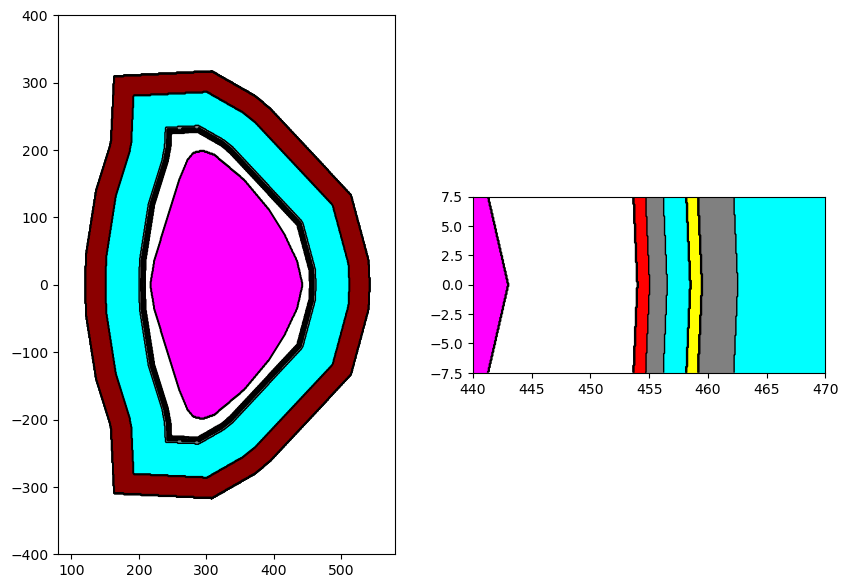

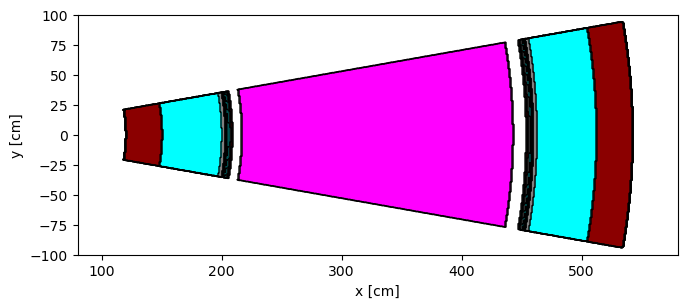

In [12]:
colors={root[0]:'magenta', root[1]:'white', root[2]:'red', root[3]:'grey', root[4]:'aqua', 
        root[5]:'yellow', root[6]:'grey', root[7]:'aqua', root[8]:'darkred', root[9]:'white'}

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10,7))
geometry.plot(origin=(330, 0, 0), basis='xz', width=[500, 800], pixels=[600, 600], axes=ax1, 
              color_by='cell', colors=colors, outline=True)
geometry.plot(origin=(455, 0, 0), basis='xz', width=[30, 15], pixels=[400, 400], axes=ax2, 
              color_by='cell', colors=colors, outline=True)
plt.show()

geometry.plot(origin=(330, 0, 0), basis='xy', width=[500, 200], pixels=[600, 600], 
              color_by='cell', colors=colors, outline=True)
plt.show()


## Results
- TBR
- Neutron spectra

In [21]:
sp = openmc.StatePoint("old/statepoint.100.h5")

In [20]:
tbr_total = helpers.extract_tbr_contributions(sp, "TBR")
tbr_cc = helpers.extract_tbr_contributions(sp, "TBR channel")
tbr_blanket = helpers.extract_tbr_contributions(sp, "TBR blanket")

df = pd.DataFrame([tbr_total, tbr_cc, tbr_blanket], index=["Total", "Channel", "Blanket"])
print(df)

              TBR  TBR std. dev.       Li6       Li7
Total    1.046292       0.000394  1.038333  0.007958
Channel  0.254792       0.000170  0.253028  0.001764
Blanket  0.791500       0.000327  0.785305  0.006195
